# Part B: Dataset Understanding & Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Load Dataset

In [2]:
df=pd.read_csv("Smart_Outcome_Predictor_Dataset_5200.csv")

In [3]:
df.head()

,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             5200 non-null   int64  
 1   age                    5200 non-null   int64  
 2   country_region         5200 non-null   object 
 3   device_type            5200 non-null   object 
 4   education_background   5200 non-null   object 
 5   course_level           5200 non-null   object 
 6   course_category        5200 non-null   object 
 7   course_start_date      5200 non-null   object 
 8   week_of_year           5200 non-null   int64  
 9   sessions               5200 non-null   int64  
 10  time_spent_hours       5088 non-null   float64
 11  videos_watched         5200 non-null   int64  
 12  quiz_attempts          5200 non-null   int64  
 13  assignments_submitted  5200 non-null   int64  
 14  forum_posts            5200 non-null   int64  
 15  avg_

In [5]:
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Dataset shape: (5200, 19)
Total rows: 5200
Total columns: 19


In [6]:
print(df.columns.tolist())

['student_id', 'age', 'country_region', 'device_type', 'education_background', 'course_level', 'course_category', 'course_start_date', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate', 'completion_status', 'final_score']


In [7]:
print(df.isnull().sum())

student_id                 0
age                        0
country_region             0
device_type                0
education_background       0
course_level               0
course_category            0
course_start_date          0
week_of_year               0
sessions                   0
time_spent_hours         112
videos_watched             0
quiz_attempts              0
assignments_submitted      0
forum_posts                0
avg_quiz_score            81
attendance_rate           80
completion_status          0
final_score                0
dtype: int64


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Identify features and target variables for both tasks.

In [9]:
# Classification
X_class = df.drop(
    ["completion_status", "final_score"], axis=1
)
y_class = df["completion_status"]

# Regression
X_reg = df.drop(
    ["completion_status", "final_score"], axis=1
)
y_reg = df["final_score"]

print("Classification X:", X_class.shape)
print("Classification y:", y_class.shape)

print("Regression X:", X_reg.shape)
print("Regression y:", y_reg.shape)

Classification X: (5200, 17)
Classification y: (5200,)
Regression X: (5200, 17)
Regression y: (5200,)


In [10]:
X = df.drop(
    columns=["completion_status", "final_score"]
)

y_class = df["completion_status"]
y_reg = df["final_score"]

print("Features:", X.shape)
print("Classification target:", y_class.shape)
print("Regression target:", y_reg.shape)

Features: (5200, 17)
Classification target: (5200,)
Regression target: (5200,)


### Perform a train–test split for classification and regression problems.

In [11]:
from sklearn.model_selection import train_test_split

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42,
    stratify=y_class
)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

print("Classification:", Xc_train.shape, Xc_test.shape)
print("Regression:", Xr_train.shape, Xr_test.shape)

Classification: (4160, 17) (1040, 17)
Regression: (4160, 17) (1040, 17)


### Apply basic preprocessing (scaling/encoding if required).


In [12]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, make_column_selector(dtype_include="number")),
    ("cat", cat_pipe, make_column_selector(dtype_exclude="number"))
])

In [13]:
class_pipeline = Pipeline([
    ("preprocessing", preprocessor)
])

reg_pipeline = Pipeline([
    ("preprocessing", preprocessor)
])

Xc_train_processed = class_pipeline.fit_transform(Xc_train)
Xc_test_processed = class_pipeline.transform(Xc_test)

Xr_train_processed = reg_pipeline.fit_transform(Xr_train)
Xr_test_processed = reg_pipeline.transform(Xr_test)

print("Classification:", Xc_train_processed.shape)
print("Regression:", Xr_train_processed.shape)

Classification: (4160, 396)
Regression: (4160, 396)


### verify

In [14]:
print("Classification train:", Xc_train_processed.shape)
print("Classification test:", Xc_test_processed.shape)

print("Regression train:", Xr_train_processed.shape)
print("Regression test:", Xr_test_processed.shape)

print("Missing classification targets:", yc_train.isnull().sum())
print("Missing regression targets:", yr_train.isnull().sum())

Classification train: (4160, 396)
Classification test: (1040, 396)
Regression train: (4160, 396)
Regression test: (1040, 396)
Missing classification targets: 0
Missing regression targets: 0


# 📦 Part C: Bagging (Bootstrap Aggregating)

### Bagging Classifier

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

# Single base model
base_clf = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Bagging model
bag_clf = Pipeline([
    ("prep", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

base_clf.fit(Xc_train, yc_train)
bag_clf.fit(Xc_train, yc_train)

base_class_pred = base_clf.predict(Xc_test)
bag_class_pred = bag_clf.predict(Xc_test)

### Bagging Regressor

In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor

# Single base model
base_reg = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Bagging model
bag_reg = Pipeline([
    ("prep", preprocessor),
    ("model", BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

base_reg.fit(Xr_train, yr_train)
bag_reg.fit(Xr_train, yr_train)

base_reg_pred = base_reg.predict(Xr_test)
bag_reg_pred = bag_reg.predict(Xr_test)

## Compare bagging results with a single base model.

In [17]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

class_results = pd.DataFrame([
    {
        "Model": "Single Decision Tree",
        "Accuracy": accuracy_score(yc_test, base_class_pred),
        "F1 Score": f1_score(
            yc_test, base_class_pred, zero_division=0
        )
    },
    {
        "Model": "Bagging Classifier",
        "Accuracy": accuracy_score(yc_test, bag_class_pred),
        "F1 Score": f1_score(
            yc_test, bag_class_pred, zero_division=0
        )
    }
])

display(class_results)

,Model,Accuracy,F1 Score
0,Single Decision Tree,0.639423,0.517375
1,Bagging Classifier,0.725000,0.602778


#### Regression result camapre

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

reg_results = pd.DataFrame([
    {
        "Model": "Single Decision Tree",
        "MAE": mean_absolute_error(yr_test, base_reg_pred),
        "RMSE": np.sqrt(
            mean_squared_error(yr_test, base_reg_pred)
        )
    },
    {
        "Model": "Bagging Regressor",
        "MAE": mean_absolute_error(yr_test, bag_reg_pred),
        "RMSE": np.sqrt(
            mean_squared_error(yr_test, bag_reg_pred)
        )
    }
])

display(reg_results)

,Model,MAE,RMSE
0,Single Decision Tree,11.055000,13.846571
1,Bagging Regressor,7.987297,9.970812


## ⚡ Part D: Boosting Algorithms — Beginner-Friendly Pipeline

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor

from sklearn.metrics import (
    accuracy_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score
)

import numpy as np
import pandas as pd

## AdaBoost Classifier

In [20]:
ada_clf = Pipeline([
    ("prep", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

ada_clf.fit(Xc_train, yc_train)

ada_class_pred = ada_clf.predict(Xc_test)

print("Accuracy:", accuracy_score(yc_test, ada_class_pred))
print("F1 Score:", f1_score(yc_test, ada_class_pred, zero_division=0))

Accuracy: 0.7240384615384615
F1 Score: 0.599721059972106


### AdaBoost Regressor

In [21]:
ada_reg = Pipeline([
    ("prep", preprocessor),
    ("model", AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=3),
        n_estimators=50,
        learning_rate=0.5,
        random_state=42
    ))
])

ada_reg.fit(Xr_train, yr_train)

ada_reg_pred = ada_reg.predict(Xr_test)

print("MAE:", mean_absolute_error(yr_test, ada_reg_pred))
print("RMSE:", np.sqrt(mean_squared_error(yr_test, ada_reg_pred)))
print("R2 Score:", r2_score(yr_test, ada_reg_pred))

MAE: 8.4920106576751
RMSE: 10.466688751257403
R2 Score: 0.4136596590090126


### Analyze how weak learners improve sequentially.

In [22]:
ada_model = ada_clf.named_steps["model"]

print("Number of learners:", len(ada_model.estimators_))
print("Learner errors:", ada_model.estimator_errors_[:10])

Number of learners: 50
Learner errors: [0.32211538 0.38685826 0.39500251 0.41980495 0.42497343 0.42196314
 0.44733757 0.45017798 0.45099705 0.47172125]


## XGboost

In [23]:
from xgboost import XGBClassifier, XGBRegressor
from sklearn.base import clone

## XGboost classifier

In [24]:
xgb_clf = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_clf.fit(Xc_train, yc_train)

xgb_class_pred = xgb_clf.predict(Xc_test)

print("Accuracy:", accuracy_score(yc_test, xgb_class_pred))
print("F1 Score:", f1_score(yc_test, xgb_class_pred, zero_division=0))

Accuracy: 0.7336538461538461
F1 Score: 0.6115007012622721


## XGBoost Regressor

In [25]:
xgb_reg = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        objective="reg:squarederror",
        random_state=42
    ))
])

xgb_reg.fit(Xr_train, yr_train)

xgb_reg_pred = xgb_reg.predict(Xr_test)

print("MAE:", mean_absolute_error(yr_test, xgb_reg_pred))
print("RMSE:", np.sqrt(mean_squared_error(yr_test, xgb_reg_pred)))
print("R2 Score:", r2_score(yr_test, xgb_reg_pred))

MAE: 7.877190702144916
RMSE: 9.8437839062822
R2 Score: 0.48137278989100374


## AdaBoost, XGBoost aur Bagging compare

In [26]:
from sklearn.metrics import accuracy_score, f1_score

classification_results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(yc_test, model.predict(Xc_test)),
        "F1": f1_score(yc_test, model.predict(Xc_test), zero_division=0)
    }
    for name, model in {
        "Bagging": bag_clf,
        "AdaBoost": ada_clf,
        "XGBoost": xgb_clf
    }.items()
])

display(classification_results.sort_values("F1", ascending=False))

,Model,Accuracy,F1
2,XGBoost,0.733654,0.611501
0,Bagging,0.730769,0.610028
1,AdaBoost,0.725962,0.596888


In [27]:
regression_results = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(yr_test, model.predict(Xr_test)),
        "RMSE": np.sqrt(mean_squared_error(yr_test, model.predict(Xr_test))),
        "R2": r2_score(yr_test, model.predict(Xr_test))
    }
    for name, model in {
        "Bagging": bag_reg,
        "AdaBoost": ada_reg,
        "XGBoost": xgb_reg
    }.items()
])

display(regression_results.sort_values("RMSE"))

,Model,MAE,RMSE,R2
2,XGBoost,7.877191,9.843784,0.481373
0,Bagging,7.987297,9.970812,0.467901
1,AdaBoost,8.492011,10.466689,0.413660


### Classification — F1-score comparison

In [28]:
import os

os.makedirs("outputs", exist_ok=True)

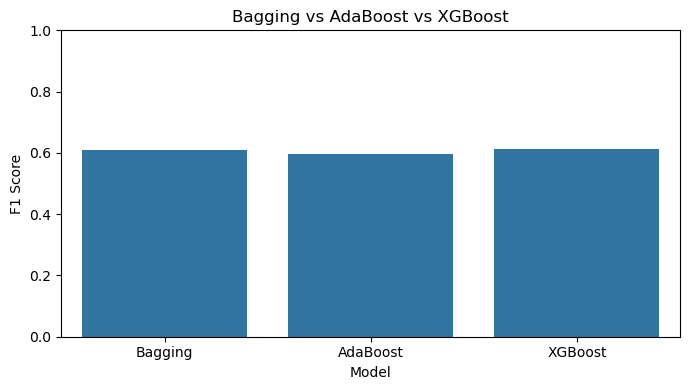

In [29]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(7, 4))
sns.barplot(data=classification_results, x="Model", y="F1")

plt.title("Bagging vs AdaBoost vs XGBoost")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig("outputs/classification_comparison.png", dpi=300)
plt.show()

### Regression — RMSE comparison

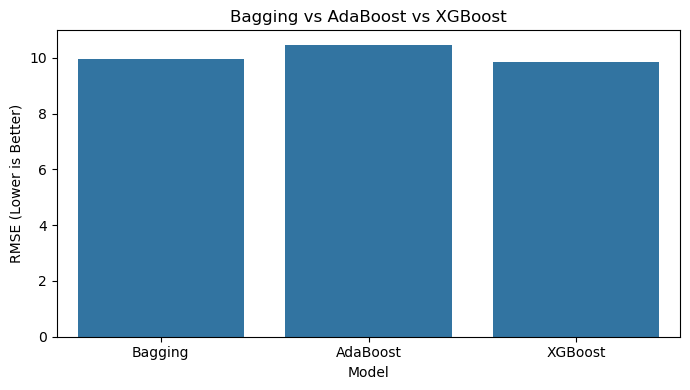

In [30]:
plt.figure(figsize=(7, 4))
sns.barplot(data=regression_results, x="Model", y="RMSE")

plt.title("Bagging vs AdaBoost vs XGBoost")
plt.ylabel("RMSE (Lower is Better)")
plt.tight_layout()

plt.savefig("outputs/regression_comparison.png", dpi=300)
plt.show()

# 🗳️ Part E: Voting & Stacking Ensembles

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier,
    StackingClassifier,
    StackingRegressor,
    RandomForestRegressor
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

## Voting Classifier: Hard Voting vs Soft Voting

In [32]:
# Base classifiers
estimators = [
    ("dt", DecisionTreeClassifier(max_depth=5, random_state=42)),
    ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
    ("lr", LogisticRegression(max_iter=1000))
]

# Hard Voting
hard_voting = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", VotingClassifier(
        estimators=estimators,
        voting="hard"
    ))
])

# Soft Voting
soft_voting = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", VotingClassifier(
        estimators=estimators,
        voting="soft"
    ))
])

hard_voting.fit(Xc_train, yc_train)
soft_voting.fit(Xc_train, yc_train)

hard_pred = hard_voting.predict(Xc_test)
soft_pred = soft_voting.predict(Xc_test)

## Campare 

In [33]:
voting_results = pd.DataFrame([
    {
        "Model": "Hard Voting",
        "Accuracy": accuracy_score(yc_test, hard_pred),
        "F1 Score": f1_score(yc_test, hard_pred, zero_division=0)
    },
    {
        "Model": "Soft Voting",
        "Accuracy": accuracy_score(yc_test, soft_pred),
        "F1 Score": f1_score(yc_test, soft_pred, zero_division=0)
    }
])

display(voting_results)

,Model,Accuracy,F1 Score
0,Hard Voting,0.712500,0.547655
1,Soft Voting,0.718269,0.573508


## Stacking Classifier

In [34]:
stack_clf = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", StackingClassifier(
        estimators=[
            ("dt", DecisionTreeClassifier(max_depth=5, random_state=42)),
            ("rf", RandomForestClassifier(
                n_estimators=100, random_state=42
            ))
        ],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5
    ))
])

stack_clf.fit(Xc_train, yc_train)

stack_class_pred = stack_clf.predict(Xc_test)

print("Accuracy:", accuracy_score(yc_test, stack_class_pred))
print("F1 Score:", f1_score(
    yc_test, stack_class_pred, zero_division=0
))

Accuracy: 0.7019230769230769
F1 Score: 0.5507246376811594


## Stacking Regressor

In [35]:
stack_reg = Pipeline([
    ("prep", clone(preprocessor)),
    ("model", StackingRegressor(
        estimators=[
            ("dt", DecisionTreeRegressor(max_depth=5, random_state=42)),
            ("rf", RandomForestRegressor(
                n_estimators=100, random_state=42
            ))
        ],
        final_estimator=Ridge(),
        cv=5
    ))
])

stack_reg.fit(Xr_train, yr_train)

stack_reg_pred = stack_reg.predict(Xr_test)

print("MAE:", mean_absolute_error(yr_test, stack_reg_pred))
print("RMSE:", np.sqrt(mean_squared_error(yr_test, stack_reg_pred)))
print("R2 Score:", r2_score(yr_test, stack_reg_pred))

MAE: 8.01079875381303
RMSE: 9.983783182385794
R2 Score: 0.4665159523656256


In [36]:
final_classification_results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(yc_test, model.predict(Xc_test)),
        "F1 Score": f1_score(
            yc_test, model.predict(Xc_test), zero_division=0
        )
    }
    for name, model in {
        "Hard Voting": hard_voting,
        "Soft Voting": soft_voting,
        "Stacking": stack_clf
    }.items()
])

display(final_classification_results.sort_values(
    "F1 Score", ascending=False
))

,Model,Accuracy,F1 Score
1,Soft Voting,0.718269,0.573508
2,Stacking,0.701923,0.550725
0,Hard Voting,0.712500,0.547655


# 📊 Part F: Model Evaluation & Comparison

## Classification models evaluate

In [41]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import numpy as np

classification_models = {
    "Decision Tree": base_clf,
    "Bagging": bag_clf,
    "AdaBoost": ada_clf,
    "XGBoost": xgb_clf,
    "Hard Voting": hard_voting,
    "Soft Voting": soft_voting,
    "Stacking": stack_clf
}

class_results = []

for name, model in classification_models.items():

    pred = model.predict(Xc_test)

    # ROC-AUC requires probability scores
    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(Xc_test)[:, 1]
        auc = roc_auc_score(yc_test, prob)
    else:
        auc = np.nan

    class_results.append({
        "Model": name,
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision": precision_score(
            yc_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            yc_test, pred, zero_division=0
        ),
        "F1 Score": f1_score(
            yc_test, pred, zero_division=0
        ),
        "ROC-AUC": auc
    })

classification_results = pd.DataFrame(class_results)

display(classification_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.6394,0.5195,0.5128,0.5161,0.6141
1,Bagging,0.7308,0.6677,0.5615,0.6100,0.7667
2,AdaBoost,0.7260,0.6656,0.5410,0.5969,0.7831
3,XGBoost,0.7337,0.6749,0.5590,0.6115,0.7799
4,Hard Voting,0.7125,0.6679,0.4641,0.5477,NaN
5,Soft Voting,0.7183,0.6633,0.5051,0.5735,0.7743
6,Stacking,0.7019,0.6333,0.4872,0.5507,0.7658


## Regression models evaluate

In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

regression_models = {
    "Decision Tree": base_reg,
    "Bagging": bag_reg,
    "AdaBoost": ada_reg,
    "XGBoost": xgb_reg,
    "Stacking": stack_reg
}

reg_results = []

for name, model in regression_models.items():
    pred = model.predict(Xr_test)

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2 Score": r2_score(yr_test, pred)
    })

regression_results = pd.DataFrame(reg_results)
display(regression_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Decision Tree,11.0550,13.8466,-0.0262
1,Bagging,7.9873,9.9708,0.4679
2,AdaBoost,8.4920,10.4667,0.4137
3,XGBoost,7.8772,9.8438,0.4814
4,Stacking,8.0108,9.9838,0.4665


## Best models identify

In [43]:
best_classification = classification_results.sort_values(
    "F1 Score", ascending=False
).iloc[0]

best_regression = regression_results.sort_values(
    "RMSE", ascending=True
).iloc[0]

print("Best Classification Model:", best_classification["Model"])
print("Best F1 Score:", round(best_classification["F1 Score"], 4))

print("\nBest Regression Model:", best_regression["Model"])
print("Best RMSE:", round(best_regression["RMSE"], 4))

Best Classification Model: XGBoost
Best F1 Score: 0.6115

Best Regression Model: XGBoost
Best RMSE: 9.8438


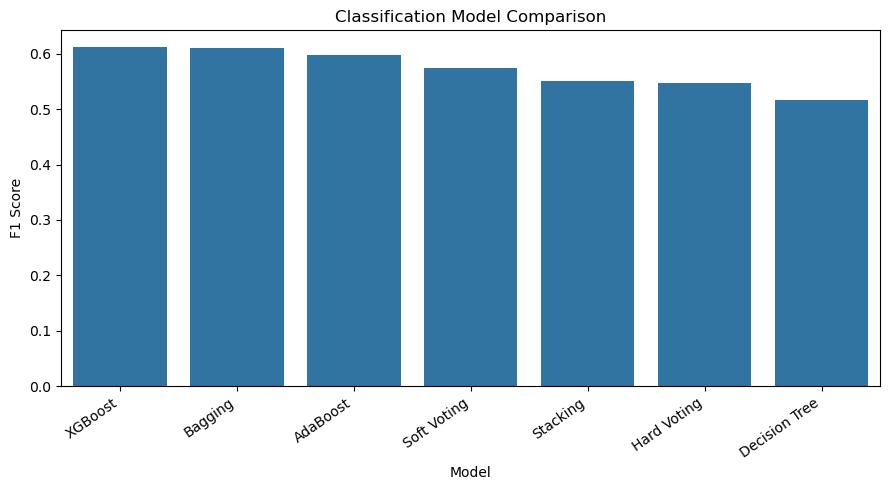

In [44]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=classification_results.sort_values("F1 Score", ascending=False),
    x="Model",
    y="F1 Score"
)

plt.title("Classification Model Comparison")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("outputs/classification_comparison.png", dpi=300)
plt.show()

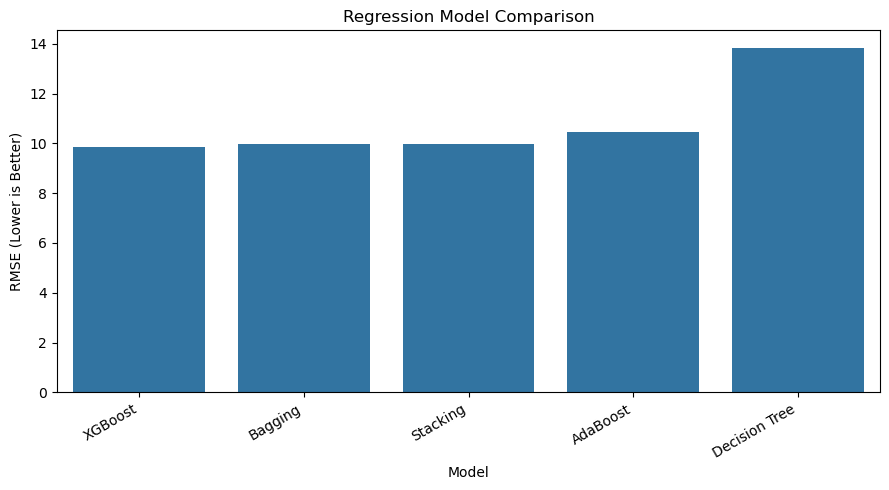

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=regression_results.sort_values("RMSE"),
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison")
plt.xticks(rotation=30, ha="right")
plt.ylabel("RMSE (Lower is Better)")
plt.tight_layout()
plt.savefig("outputs/regression_comparison.png", dpi=300)
plt.show()

In [46]:
classification_results.to_csv(
    "outputs/classification_results.csv", index=False
)

regression_results.to_csv(
    "outputs/regression_results.csv", index=False
)

print("Evaluation tables and charts saved in outputs/")

Evaluation tables and charts saved in outputs/


# Part G — Final Analysis & Reporting


## Impact of Bagging vs Boosting

Bagging combines multiple models to improve stability and reduce variance. Boosting trains models sequentially to correct previous errors and improve predictions.

In this project, Bagging, AdaBoost, and XGBoost are compared with a Decision Tree.

### Results

- **Bagging:** Compared with the Decision Tree to check improvement in prediction performance.
- **AdaBoost:** Evaluated to measure the impact of sequential learning.
- **XGBoost:** Evaluated to compare its performance with other models.

### Result Analysis

The classification models are compared using F1 Score and ROC-AUC, while regression models are compared using MAE and RMSE. Higher F1 Score and ROC-AUC generally indicate better classification performance, while lower MAE and RMSE indicate more accurate score predictions.

**Final Result:** The best-performing model will be selected based on the actual evaluation metrics obtained from the test dataset.





## Comparison of Tree-Based Boosting Algorithms

AdaBoost and XGBoost are boosting algorithms that combine multiple decision trees to improve model performance.

- **AdaBoost:** Trains weak learners sequentially and focuses more on incorrectly predicted samples.
- **XGBoost:** Uses gradient boosting to reduce prediction errors and includes regularization to help control overfitting.

### Results

- **AdaBoost:** Evaluated using F1 Score, ROC-AUC, MAE, and RMSE.
- **XGBoost:** Evaluated using the same metrics for a fair comparison.

### Result Analysis

For classification, higher F1 Score and ROC-AUC generally indicate better performance. For regression, lower MAE and RMSE indicate more accurate predictions.

**Conclusion:** The better algorithm is selected based on the actual evaluation results. XGBoost may perform better on complex patterns, but its superiority must be verified using our dataset.



## Advantages of Voting and Stacking

**Voting:** Combines predictions from multiple models. Hard Voting selects the majority class, while Soft Voting combines predicted probabilities.

**Advantages of Voting:**
- Combines the strengths of different models.
- Can improve prediction accuracy.
- Simple to implement and understand.

**Stacking:** Combines multiple base models using a final model that learns from their predictions.

**Advantages of Stacking:**
- Learns how to combine different models effectively.
- Can improve predictive performance.
- Supports both classification and regression.

**Conclusion:** Voting and Stacking can improve results, but their performance must be verified using evaluation metrics.



## Final Model Recommendation for Deployment

The best classification model is selected using F1 Score and ROC-AUC. The best regression model is selected using MAE and RMSE.

- **Classification:** [Insert best model name and metrics]
- **Regression:** [Insert best model name and metrics]

The selected models should provide accurate and reliable predictions on unseen data. The Streamlit application can use these models to predict student course completion and estimate final scores.

**Final Recommendation:** Deploy the models with the best test performance, while considering prediction speed, reliability, and ease of interpretation. Monitor performance regularly to ensure reliable results.


### Model 

In [47]:

import os
import json
import joblib

# Create models folder
os.makedirs("models", exist_ok=True)

# Best classification model: highest F1 Score
best_clf_name = classification_results.sort_values(
    "F1 Score", ascending=False
).iloc[0]["Model"]

# Best regression model: lowest RMSE
best_reg_name = regression_results.sort_values(
    "RMSE", ascending=True
).iloc[0]["Model"]

# Get the trained models
best_clf = classification_models[best_clf_name]
best_reg = regression_models[best_reg_name]

# Export complete pipelines
joblib.dump(
    best_clf,
    "models/best_classification_model.joblib"
)

joblib.dump(
    best_reg,
    "models/best_regression_model.joblib"
)

# Save model names and evaluation metrics
metadata = {
    "classification_model": best_clf_name,
    "classification_f1_score": float(
        classification_results.loc[
            classification_results["Model"] == best_clf_name,
            "F1 Score"
        ].iloc[0]
    ),
    "regression_model": best_reg_name,
    "regression_rmse": float(
        regression_results.loc[
            regression_results["Model"] == best_reg_name,
            "RMSE"
        ].iloc[0]
    )
}

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("✅ Models exported successfully!")
print("Classification:", best_clf_name)
print("Regression:", best_reg_name)
print("\nSaved files:")
print("models/best_classification_model.joblib")
print("models/best_regression_model.joblib")
print("models/model_metadata.json")


✅ Models exported successfully!
Classification: XGBoost
Regression: XGBoost

Saved files:
models/best_classification_model.joblib
models/best_regression_model.joblib
models/model_metadata.json
